In [4]:
import pandas as pd

df = pd.read_csv("data/MachineLearningCVE/Friday-WorkingHours-Morning.pcap_ISCX.csv")
df.columns = df.columns.str.strip()

print(df.shape)
print(df["Label"].value_counts())

(191033, 79)
Label
BENIGN    189067
Bot         1966
Name: count, dtype: int64


In [5]:
import numpy as np

print(df.isna().sum().sum(), "missing values")
print(np.isinf(df.select_dtypes(include=np.number)).sum().sum(), "infinite values")
print(df.duplicated().sum(), "duplicate rows")

28 missing values
216 infinite values
6888 duplicate rows


In [6]:
before = len(df)

df = df.replace([np.inf, -np.inf], np.nan).dropna()
df = df.drop_duplicates()

print(f"Rows: {before} -> {len(df)}")
print(df["Label"].value_counts())

Rows: 191033 -> 184044
Label
BENIGN    182096
Bot         1948
Name: count, dtype: int64


In [7]:
from src.load_data import load_all

df = load_all()
print(df.shape)
print(df["Label"].value_counts())
print(df.groupby("Day")["is_attack"].agg(["count", "sum"]))

(2497980, 81)
Label
BENIGN                          2072254
DoS Hulk                         172846
DDoS                             128014
PortScan                          90694
DoS GoldenEye                     10282
FTP-Patator                        5931
DoS slowloris                      5374
DoS Slowhttptest                   5228
SSH-Patator                        3219
Bot                                1948
Web Attack --- Brute Force         1470
Web Attack --- XSS                  652
Infiltration                         36
Web Attack --- Sql Injection         21
Heartbleed                           11
Name: count, dtype: int64
            count     sum
Day                      
Friday     615420  220656
Monday     492605       0
Thursday   396897    2179
Tuesday    406467    9150
Wednesday  586591  193741


In [8]:
from src.split import get_split

X_train, X_test, y_train, y_test, label_train, label_test = get_split()

print(X_train.shape, X_test.shape)
print("Attack rate - train:", y_train.mean().round(4), " test:", y_test.mean().round(4))
print(label_test.value_counts().tail(4))

(1748586, 78) (749394, 78)
Attack rate - train: 0.1704  test: 0.1704
Label
Web Attack --- XSS              196
Infiltration                     11
Web Attack --- Sql Injection      6
Heartbleed                        3
Name: count, dtype: int64


In [9]:
import os, joblib
from sklearn.dummy import DummyClassifier
from sklearn.ensemble import RandomForestClassifier
from src.evaluate import evaluate, recall_by_attack

dummy = DummyClassifier(strategy="most_frequent").fit(X_train, y_train)
evaluate(y_test, dummy.predict(X_test), "Always predict benign")

rf = RandomForestClassifier(n_estimators=50, n_jobs=-1, random_state=42)
rf.fit(X_train, y_train)
pred = rf.predict(X_test)
evaluate(y_test, pred, "Random Forest")
print(recall_by_attack(label_test, pred))

os.makedirs("models", exist_ok=True)
joblib.dump(rf, "models/rf.joblib")

--- Always predict benign ---
Precision: 0.0000
Recall:    0.0000
F1:        0.0000
Missed attacks (FN): 127718   False alarms (FP): 0

--- Random Forest ---
Precision: 0.9964
Recall:    0.9954
F1:        0.9959
Missed attacks (FN): 592   False alarms (FP): 457

label
Heartbleed                      0.666667
Web Attack --- Sql Injection    0.666667
Infiltration                    0.727273
Bot                             0.774359
Web Attack --- XSS              0.948980
PortScan                        0.990260
Web Attack --- Brute Force      0.993197
DoS Slowhttptest                0.995536
SSH-Patator                     0.995859
DoS GoldenEye                   0.997083
DoS Hulk                        0.997242
DoS slowloris                   0.997519
DDoS                            0.999766
FTP-Patator                     1.000000
Name: flagged, dtype: float64


['models/rf.joblib']

In [10]:
cols = ["Flow Packets/s", "Total Fwd Packets", "Total Backward Packets",
        "Flow Duration", "SYN Flag Count", "Destination Port"]

profile = X_train[cols].assign(is_attack=y_train.values)
print(profile.groupby("is_attack")[cols].quantile([0.1, 0.5, 0.9]).round(1))

               Flow Packets/s  Total Fwd Packets  Total Backward Packets  \
is_attack                                                                  
0         0.1             0.5                1.0                     0.0   
          0.5            84.5                2.0                     2.0   
          0.9         47619.0               15.0                    13.0   
1         0.1             0.1                1.0                     0.0   
          0.5             1.1                4.0                     5.0   
          0.9         41666.7                8.0                     7.0   

               Flow Duration  SYN Flag Count  Destination Port  
is_attack                                                       
0         0.1           50.0             0.0              53.0  
          0.5        46294.0             0.0              80.0  
          0.9     61192820.8             0.0           52478.0  
1         0.1           48.0             0.0              80.0  
 

In [11]:
import pandas as pd

rules = {
    "R1 FTP/SSH port": X_train["Destination Port"].isin([21, 22]),
    "R2 long chatty flow": (X_train["Flow Duration"] > 1_000_000) & (X_train["Total Fwd Packets"] >= 3),
    "R3 tiny non-DNS probe": (X_train["Total Fwd Packets"] <= 2) & (X_train["Total Backward Packets"] <= 1) & (X_train["Destination Port"] != 53),
    "R4 high packet rate": X_train["Flow Packets/s"] > 10_000,
}

rows = []
for name, flagged in rules.items():
    tp = (flagged & (y_train == 1)).sum()
    rows.append({"rule": name, "flagged": flagged.sum(),
                 "precision": tp / max(flagged.sum(), 1),
                 "recall": tp / y_train.sum()})
print(pd.DataFrame(rows).round(3).to_string(index=False))

                 rule  flagged  precision  recall
      R1 FTP/SSH port    13673      0.493   0.023
  R2 long chatty flow   496077      0.356   0.593
R3 tiny non-DNS probe   394865      0.178   0.235
  R4 high packet rate   515113      0.127   0.219


In [12]:
from src.rules import rule_based_predict

rule_pred = rule_based_predict(X_test)
evaluate(y_test, rule_pred, "Rule-based (R1 + R2)")
print(recall_by_attack(label_test, rule_pred))

--- Rule-based (R1 + R2) ---
Precision: 0.3558
Recall:    0.5968
F1:        0.4458
Missed attacks (FN): 51498   False alarms (FP): 138002

label
PortScan                        0.006064
Bot                             0.179487
DDoS                            0.654463
Web Attack --- Sql Injection    0.666667
DoS slowloris                   0.674318
DoS GoldenEye                   0.712156
DoS Slowhttptest                0.806122
DoS Hulk                        0.827728
Web Attack --- Brute Force      0.900227
Web Attack --- XSS              0.954082
Heartbleed                      1.000000
FTP-Patator                     1.000000
SSH-Patator                     1.000000
Infiltration                    1.000000
Name: flagged, dtype: float64


        model  precision  recall     f1  missed  false_alarms
   Rule-based     0.3558  0.5968 0.4458   51498        138002
Random Forest     0.9964  0.9954 0.9959     592           457


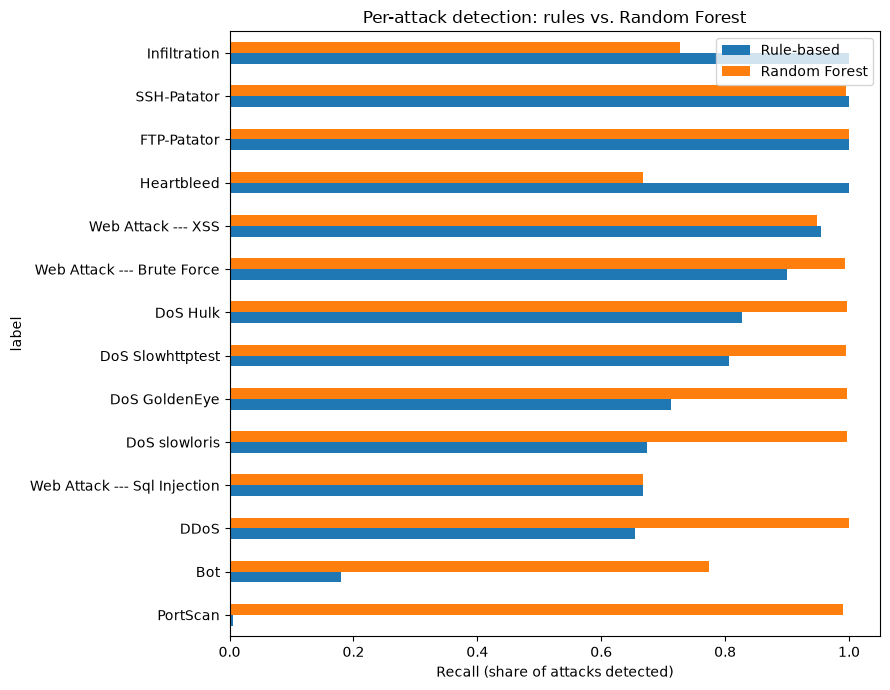

In [13]:
import matplotlib.pyplot as plt
from sklearn.metrics import f1_score, precision_score, recall_score

rows = []
for name, p in [("Rule-based", rule_pred), ("Random Forest", pred)]:
    rows.append({"model": name,
                 "precision": precision_score(y_test, p),
                 "recall": recall_score(y_test, p),
                 "f1": f1_score(y_test, p),
                 "missed": int(((y_test == 1) & (p == 0)).sum()),
                 "false_alarms": int(((y_test == 0) & (p == 1)).sum())})
print(pd.DataFrame(rows).round(4).to_string(index=False))

comp = pd.DataFrame({"Rule-based": recall_by_attack(label_test, rule_pred),
                     "Random Forest": recall_by_attack(label_test, pred)}).sort_values("Rule-based")
ax = comp.plot.barh(figsize=(9, 7))
ax.set_xlabel("Recall (share of attacks detected)")
ax.set_title("Per-attack detection: rules vs. Random Forest")
plt.tight_layout()
os.makedirs("figures", exist_ok=True)
plt.savefig("figures/per_attack_recall.png", dpi=150)
plt.show()

In [14]:
imp = pd.Series(rf.feature_importances_, index=X_train.columns).sort_values(ascending=False)
print(imp.head(15).round(4))

Max Packet Length              0.0857
Packet Length Variance         0.0850
Packet Length Std              0.0832
Avg Bwd Segment Size           0.0734
Bwd Packet Length Max          0.0554
Average Packet Size            0.0413
Total Length of Bwd Packets    0.0389
Bwd Packet Length Std          0.0383
Bwd Packet Length Mean         0.0351
Subflow Fwd Bytes              0.0267
Destination Port               0.0244
Subflow Fwd Packets            0.0226
Total Fwd Packets              0.0193
Total Length of Fwd Packets    0.0177
Fwd IAT Max                    0.0170
dtype: float64


In [15]:
from src.evasion import perturb

atk = X_test[y_test == 1]
print("strength   RF recall   Rule recall")
for s in [0, 0.1, 0.25, 0.5, 0.9]:
    Xp = perturb(atk, s)
    print(f"{s:>8}   {rf.predict(Xp).mean():.4f}      {rule_based_predict(Xp).mean():.4f}")

strength   RF recall   Rule recall
       0   0.9954      0.5968
     0.1   0.9950      0.5697
    0.25   0.9934      0.5689
     0.5   0.9527      0.5427
     0.9   0.9038      0.4535


In [16]:
atk_labels = label_test[y_test == 1]

comp = pd.DataFrame({
    "clean": recall_by_attack(atk_labels, rf.predict(atk)),
    "perturbed 0.5": recall_by_attack(atk_labels, rf.predict(perturb(atk, 0.5))),
}).sort_values("perturbed 0.5")
print(comp.round(3))

                              clean  perturbed 0.5
label                                             
Bot                           0.774          0.665
Web Attack --- Sql Injection  0.667          0.667
Infiltration                  0.727          0.727
PortScan                      0.990          0.823
DoS slowloris                 0.998          0.953
Web Attack --- XSS            0.949          0.954
DoS GoldenEye                 0.997          0.961
DDoS                          1.000          0.989
Web Attack --- Brute Force    0.993          0.991
SSH-Patator                   0.996          0.992
DoS Slowhttptest              0.996          0.992
DoS Hulk                      0.997          0.993
Heartbleed                    0.667          1.000
FTP-Patator                   1.000          1.000


In [17]:
import warnings
warnings.filterwarnings("ignore")
from sklearn.ensemble import HistGradientBoostingClassifier
from sklearn.linear_model import LogisticRegression
from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import StandardScaler
from sklearn.tree import DecisionTreeClassifier

models = {
    "Logistic Regression": make_pipeline(StandardScaler(), LogisticRegression(max_iter=200)),
    "Decision Tree": DecisionTreeClassifier(random_state=42),
    "Gradient Boosting": HistGradientBoostingClassifier(random_state=42),
    "Random Forest": rf,
}

for name, m in models.items():
    if name != "Random Forest":
        m.fit(X_train, y_train)
    evaluate(y_test, m.predict(X_test), name)

--- Logistic Regression ---
Precision: 0.8808
Recall:    0.8615
F1:        0.8710
Missed attacks (FN): 17687   False alarms (FP): 14895

--- Decision Tree ---
Precision: 0.9959
Recall:    0.9952
F1:        0.9956
Missed attacks (FN): 607   False alarms (FP): 526

--- Gradient Boosting ---
Precision: 0.9962
Recall:    0.9983
F1:        0.9972
Missed attacks (FN): 214   False alarms (FP): 492

--- Random Forest ---
Precision: 0.9964
Recall:    0.9954
F1:        0.9959
Missed attacks (FN): 592   False alarms (FP): 457



In [18]:
print("strength  " + "  ".join(f"{n[:12]:>12}" for n in models))
for s in [0, 0.25, 0.5, 0.9]:
    Xp = perturb(atk, s)
    print(f"{s:>8}  " + "  ".join(f"{m.predict(Xp).mean():>12.4f}" for m in models.values()))

strength  Logistic Reg  Decision Tre  Gradient Boo  Random Fores
       0        0.8615        0.9952        0.9983        0.9954
    0.25        0.8155        0.9018        0.9519        0.9934
     0.5        0.7638        0.8404        0.9487        0.9527
     0.9        0.7288        0.8127        0.8835        0.9038


In [19]:
gb = models["Gradient Boosting"]

for s in [0.5, 0.9]:
    for name, m in [("Random Forest", rf), ("Gradient Boosting", gb)]:
        r = [m.predict(perturb(atk, s, seed=k)).mean() for k in range(5)]
        print(f"strength {s}  {name:<18} {np.mean(r):.4f} +/- {np.std(r):.4f}")

comp = pd.DataFrame({
    "RF clean": recall_by_attack(atk_labels, rf.predict(atk)),
    "RF 0.5": recall_by_attack(atk_labels, rf.predict(perturb(atk, 0.5))),
    "GB clean": recall_by_attack(atk_labels, gb.predict(atk)),
    "GB 0.5": recall_by_attack(atk_labels, gb.predict(perturb(atk, 0.5))),
}).sort_values("GB 0.5")
print(comp.round(3))

strength 0.5  Random Forest      0.9526 +/- 0.0005
strength 0.5  Gradient Boosting  0.9481 +/- 0.0004
strength 0.9  Random Forest      0.9035 +/- 0.0007
strength 0.9  Gradient Boosting  0.8831 +/- 0.0006
                              RF clean  RF 0.5  GB clean  GB 0.5
label                                                           
Web Attack --- Sql Injection     0.667   0.667     0.667   0.500
Bot                              0.774   0.665     0.721   0.602
Heartbleed                       0.667   1.000     0.667   0.667
DDoS                             1.000   0.989     1.000   0.837
Infiltration                     0.727   0.727     0.909   0.909
Web Attack --- XSS               0.949   0.954     0.980   0.974
DoS slowloris                    0.998   0.953     0.995   0.992
Web Attack --- Brute Force       0.993   0.991     0.993   0.993
DoS Slowhttptest                 0.996   0.992     0.997   0.996
SSH-Patator                      0.996   0.992     0.997   0.997
DoS GoldenEye   

In [20]:
rf_p = rf.predict_proba(X_test)[:, 1]
gb_p = gb.predict_proba(X_test)[:, 1]

soft = ((rf_p + gb_p) / 2 > 0.5).astype("int8")
either = ((rf_p > 0.5) | (gb_p > 0.5)).astype("int8")

evaluate(y_test, soft, "Soft vote (RF + GB)")
evaluate(y_test, either, "Flag if either flags")

--- Soft vote (RF + GB) ---
Precision: 0.9966
Recall:    0.9981
F1:        0.9974
Missed attacks (FN): 247   False alarms (FP): 430

--- Flag if either flags ---
Precision: 0.9954
Recall:    0.9990
F1:        0.9972
Missed attacks (FN): 133   False alarms (FP): 596



In [21]:
def ensemble_recall(Xp):
    a = rf.predict_proba(Xp)[:, 1]
    b = gb.predict_proba(Xp)[:, 1]
    return ((a + b) / 2 > 0.5).mean(), ((a > 0.5) | (b > 0.5)).mean()

for s in [0.5, 0.9]:
    soft_r, either_r = ensemble_recall(perturb(atk, s))
    print(f"strength {s}  soft vote {soft_r:.4f}  either {either_r:.4f}")

strength 0.5  soft vote 0.9850  either 0.9970
strength 0.9  soft vote 0.9203  either 0.9655


In [22]:
import sys
import numpy as np
import pandas as pd
import sklearn
from sklearn.metrics import f1_score, precision_score, recall_score

print("env:", sys.version.split()[0], "numpy", np.__version__,
      "pandas", pd.__version__, "sklearn", sklearn.__version__)

gb = models["Gradient Boosting"]
atk = X_test[y_test == 1]
atk_labels = label_test[y_test == 1]

a = rf.predict_proba(X_test)[:, 1]
b = gb.predict_proba(X_test)[:, 1]
preds = {
    "Rule-based": rule_based_predict(X_test),
    "Logistic Regression": models["Logistic Regression"].predict(X_test),
    "Decision Tree": models["Decision Tree"].predict(X_test),
    "Random Forest": rf.predict(X_test),
    "Gradient Boosting": gb.predict(X_test),
    "Soft vote": ((a + b) / 2 > 0.5).astype("int8"),
    "Either flags": ((a > 0.5) | (b > 0.5)).astype("int8"),
}
rows = [{"model": n,
         "precision": precision_score(y_test, p),
         "recall": recall_score(y_test, p),
         "f1": f1_score(y_test, p),
         "missed": int(((y_test == 1) & (p == 0)).sum()),
         "false_alarms": int(((y_test == 0) & (p == 1)).sum())}
        for n, p in preds.items()]
print(pd.DataFrame(rows).round(4).to_string(index=False))

def detect_rates(Xp):
    a = rf.predict_proba(Xp)[:, 1]
    b = gb.predict_proba(Xp)[:, 1]
    return {
        "Rule-based": rule_based_predict(Xp).mean(),
        "Logistic Regression": models["Logistic Regression"].predict(Xp).mean(),
        "Decision Tree": models["Decision Tree"].predict(Xp).mean(),
        "Random Forest": rf.predict(Xp).mean(),
        "Gradient Boosting": gb.predict(Xp).mean(),
        "Soft vote": ((a + b) / 2 > 0.5).mean(),
        "Either flags": ((a > 0.5) | (b > 0.5)).mean(),
    }

print(pd.DataFrame({s: detect_rates(perturb(atk, s)) for s in [0, 0.25, 0.5, 0.9]}).round(4))

for s in [0.5, 0.9]:
    for name, m in [("Random Forest", rf), ("Gradient Boosting", gb)]:
        r = [m.predict(perturb(atk, s, seed=k)).mean() for k in range(5)]
        print(f"strength {s}  {name:<18} {np.mean(r):.4f} +/- {np.std(r):.4f}")

comp = pd.DataFrame({
    "RF clean": recall_by_attack(atk_labels, rf.predict(atk)),
    "RF 0.5": recall_by_attack(atk_labels, rf.predict(perturb(atk, 0.5))),
    "GB clean": recall_by_attack(atk_labels, gb.predict(atk)),
    "GB 0.5": recall_by_attack(atk_labels, gb.predict(perturb(atk, 0.5))),
}).sort_values("GB 0.5")
print(comp.round(3))

env: 3.12.2 numpy 2.5.4 pandas 3.1.0 sklearn 1.9.1
              model  precision  recall     f1  missed  false_alarms
         Rule-based     0.3558  0.5968 0.4458   51498        138002
Logistic Regression     0.8808  0.8615 0.8710   17687         14895
      Decision Tree     0.9959  0.9952 0.9956     607           526
      Random Forest     0.9964  0.9954 0.9959     592           457
  Gradient Boosting     0.9962  0.9983 0.9972     214           492
          Soft vote     0.9966  0.9981 0.9974     247           430
       Either flags     0.9954  0.9990 0.9972     133           596
                       0.00    0.25    0.50    0.90
Rule-based           0.5968  0.5689  0.5427  0.4535
Logistic Regression  0.8615  0.8155  0.7638  0.7288
Decision Tree        0.9952  0.9018  0.8404  0.8127
Random Forest        0.9954  0.9934  0.9527  0.9038
Gradient Boosting    0.9983  0.9519  0.9487  0.8835
Soft vote            0.9981  0.9914  0.9850  0.9203
Either flags         0.9990  0.9983  0.99